# Avaliação prática — classificação de roupas com PyTorch

**MLP, CNN própria e transferência de aprendizado** no FashionMNIST.

**Entrega:** este notebook preenchido, preservando os IDs `q1` a `q10` das células de resposta. Não renomeie funções ou assinaturas. Código auxiliar da solução deve ficar dentro da função/classe pedida; a correção importa apenas essas definições. Não dependa de variáveis globais além dos imports fornecidos.

**Ambiente:** Python 3.10+, PyTorch e torchvision compatíveis, NumPy, Pillow e matplotlib. No Colab, use o ambiente PyTorch disponível; localmente, use o requirements fornecido. Execute de cima para baixo. Internet é necessária para baixar FashionMNIST e pesos ImageNet na primeira execução. GPU é recomendada para os experimentos.

**Protocolo:** 51.000 imagens para treino, 9.000 para validação e 10.000 do teste oficial. Use validação para escolher configurações; consulte teste apenas depois de fixar as três configurações. Sementes ajudam a reprodução, mas GPU pode apresentar pequenas diferenças.


## Como executar e entregar

1. Abra https://colab.research.google.com/ e use **Arquivo → Fazer upload de notebook** para abrir este `.ipynb`.
2. Em **Ambiente de execução → Alterar tipo de ambiente de execução**, selecione uma GPU disponível (por exemplo, T4). A primeira célula deve mostrar `Dispositivo: cuda`; `cpu` funciona, mas a ResNet18 será mais lenta.
3. As respostas Q1–Q10 já estão preenchidas e comentadas. Não altere os IDs, nomes, assinaturas ou retornos.
4. O arquivo mantém `QUICK = True`, como no original: 2.048 exemplos de treino, 512 de validação e 512 de teste, com uma época. Isso serve somente para verificar o fluxo.
5. Para a comparação com o protocolo completo, defina **QUICK = False** antes da execução final: 51.000 exemplos de treino, 9.000 de validação, 10.000 de teste e três épocas. Use GPU. Não escolha configurações com base no teste.
6. Se estiver ajustando configurações, execute somente até a célula de experimentos e observe `val_loss`. Depois de fixar as três configurações, execute a avaliação final. Para apenas verificar o fluxo QUICK antes disso, pare antes da avaliação de teste.
7. Para entregar, execute **Ambiente de execução → Executar tudo**, espere todas as células terminarem sem erro e baixe em **Arquivo → Fazer download → Fazer download do .ipynb**. Anexe o arquivo baixado, que conterá suas saídas e gráficos.

### Entendendo a solução

- **Q1–Q2:** divisão reprodutível e loaders; só treino é embaralhado.
- **Q3–Q4:** MLP com logits, CrossEntropyLoss e Adam somente nos pesos treináveis.
- **Q5–Q6:** treino e validação; a loss é ponderada pelo tamanho de cada lote. BatchNorm congelada permanece em avaliação.
- **Q7:** inferência sem gradientes, probabilidades e acurácia.
- **Q8:** CNN com duas convoluções e dois poolings; a saída espacial é 7×7, com 32 canais.
- **Q9–Q10:** ResNet18 ImageNet congelada, treinando apenas `fc`; três canais e normalização oficial aplicada uma única vez.

Nenhum normalizador é ajustado com dados de teste. MLP/CNN usam ToTensor; ResNet18 usa estatísticas ImageNet já definidas nos pesos. As funções de resposta não dependem de variáveis dos experimentos. `fit` usa as funções `train_step` e `validation_step`, conforme pedido.

### Leitura dos resultados

Loss menor indica melhor ajuste à respectiva partição. Compare modelos pela validação durante o desenvolvimento. Na avaliação final, acurácia 0,85 significa 85% de acertos. Na matriz de confusão, linhas representam classes reais e colunas as previstas; acertos ficam na diagonal. Com uma época não é possível analisar bem a tendência das curvas.

### Execução local e problemas comuns

Prefira o requirements fornecido pelo professor, com torch/torchvision compatíveis, e abra o notebook no Jupyter ou no VS Code com a extensão Jupyter. Se um download falhar, confira internet e tente a célula novamente; não substitua os pesos por `weights=None`. Se faltar memória de GPU na ResNet18, reduza `batch_size=32` para 16 ou 8 no loader de transferência e reinicie a execução. Não altere as sementes.

**Validação desta entrega:** sintaxe e preservação dos IDs/assinaturas verificadas. O treinamento real e os downloads não foram executados neste ambiente. Execute o notebook antes de entregar; não há métricas inventadas nem saídas de treinamento pré-preenchidas.


In [1]:
import random
import numpy as np
import torch
from torch import nn, optim
from torch.utils import data
from torchvision import datasets, transforms, models
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Dispositivo:', DEVICE)


Dispositivo: cpu


## Q1 — Separação dos dados

Implemente `split_dataset(dataset, val_fraction=0.15, seed=42)`. Retorne dois Subset, treino e validação, usando `data.random_split`, com `int(len(dataset)*val_fraction)` exemplos na validação. Os índices devem ser disjuntos, cobrir toda a base e ser reproduzíveis pela semente. Rejeite frações fora de (0,1) e partições vazias com ValueError. O teste oficial é carregado separadamente e nunca participa da divisão.


In [2]:
def split_dataset(dataset, val_fraction=0.15, seed=42):
    if not 0 < val_fraction < 1:
        raise ValueError("val_fraction deve estar entre 0 e 1.")
    n_valid = int(len(dataset) * val_fraction)
    n_train = len(dataset) - n_valid
    if n_train == 0 or n_valid == 0:
        raise ValueError("As duas partições devem conter exemplos.")
    generator = torch.Generator().manual_seed(seed)
    return data.random_split(dataset, [n_train, n_valid], generator=generator)


## Q2 — Dataloaders 

Implemente `make_loaders(train_ds, valid_ds, test_ds, batch_size=128, num_workers=0)`. Retorne uma tupla de três DataLoaders nessa ordem. Embaralhe somente treino; use `drop_last=False` e `pin_memory=torch.cuda.is_available()`. Respeite os argumentos.


In [3]:
def make_loaders(train_ds, valid_ds, test_ds, batch_size=128, num_workers=0):
    options = dict(batch_size=batch_size, num_workers=num_workers,
                   drop_last=False, pin_memory=torch.cuda.is_available())
    return (data.DataLoader(train_ds, shuffle=True, **options),
            data.DataLoader(valid_ds, shuffle=False, **options),
            data.DataLoader(test_ds, shuffle=False, **options))


## Q3 — MLP

Crie `MyMLP(input_size=784, n_classes=10)`: Flatten → Linear(input_size,256) → ReLU → Linear(256,n_classes). `forward(x)` deve retornar logits, sem Softmax. Respeite ambos os argumentos, inclusive para outras quantidades de classes.


In [4]:
class MyMLP(nn.Module):
    def __init__(self, input_size=784, n_classes=10):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Flatten(), nn.Linear(input_size, 256), nn.ReLU(),
            nn.Linear(256, n_classes))

    def forward(self, x):
        # CrossEntropyLoss recebe logits: não aplicar Softmax aqui.
        return self.layers(x)


## Q4 — Loss e otimizador

Implemente `make_optimization(model, lr=1e-4)`. Retorne `(loss_fn, optimizer)`, usando CrossEntropyLoss e Adam, apenas com parâmetros treináveis, e respeite o learning rate recebido.


In [5]:
def make_optimization(model, lr=1e-4):
    loss_fn = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        (p for p in model.parameters() if p.requires_grad), lr=lr)
    return loss_fn, optimizer


## Q5 — Treino e validação

Implemente `train_step(model, loader, loss_fn, optimizer, device)` e `validation_step(model, loader, loss_fn, device)`. Retorne a loss média por exemplo (float), ponderando o tamanho dos lotes, inclusive o último incompleto. Assuma loss com reduction="mean". Treino deve ativar train, mover entradas/rótulos, zerar gradientes a cada lote, prever, calcular loss, backward e step. Na validação: eval, sem gradientes, sem alterações de parâmetros. Rejeite loaders vazios com ValueError. Para transferência, depois de model.train(), coloque em eval cada BatchNorm cujos parâmetros estejam todos congelados: isso preserva suas estatísticas.


In [6]:
def train_step(model, loader, loss_fn, optimizer, device):
    model.to(device)
    model.train()
    # Congelar pesos não congela as estatísticas móveis de BatchNorm.
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d,
                               nn.SyncBatchNorm)):
            if all(not p.requires_grad for p in module.parameters()):
                module.eval()
    total_loss, total_samples = 0.0, 0
    for inputs, targets in loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        logits = model(inputs)
        loss = loss_fn(logits, targets)
        loss.backward()
        optimizer.step()
        batch_size = targets.shape[0]
        total_loss += loss.item() * batch_size
        total_samples += batch_size
    if total_samples == 0:
        raise ValueError("O loader de treino está vazio.")
    return float(total_loss / total_samples)


def validation_step(model, loader, loss_fn, device):
    model.to(device)
    model.eval()
    total_loss, total_samples = 0.0, 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            loss = loss_fn(model(inputs), targets)
            batch_size = targets.shape[0]
            total_loss += loss.item() * batch_size
            total_samples += batch_size
    if total_samples == 0:
        raise ValueError("O loader de validação está vazio.")
    return float(total_loss / total_samples)


## Q6 — Laço de treinamento

Implemente `fit(model, train_dl, valid_dl, loss_fn, optimizer, device, epochs=3)`, chamando train_step e validation_step uma vez por época nessa ordem. Retorne `{"train_loss": [...], "val_loss": [...]}` com floats, na ordem das épocas. Zero épocas retorna listas vazias; epochs negativo gera ValueError. O conjunto de teste não é argumento desta função.


In [7]:
def fit(model, train_dl, valid_dl, loss_fn, optimizer, device, epochs=3):
    if epochs < 0:
        raise ValueError("epochs não pode ser negativo.")
    history = {"train_loss": [], "val_loss": []}
    for epoch in range(epochs):
        train_loss = train_step(model, train_dl, loss_fn, optimizer, device)
        val_loss = validation_step(model, valid_dl, loss_fn, device)
        history["train_loss"].append(float(train_loss))
        history["val_loss"].append(float(val_loss))
        print(f"Época {epoch + 1}/{epochs} | treino: {train_loss:.4f} | "
              f"validação: {val_loss:.4f}")
    return history


## Q7 — Predições e métricas

Implemente `predict(model, loader, device)`. Use eval e ausência de gradientes. Retorne dicionário com `probs` (tensor CPU N×C, Softmax dim=1), `preds` e `targets` (tensores CPU long de tamanho N), `accuracy` (float entre 0 e 1). Preserve a ordem do loader. Rejeite loader vazio com ValueError. Nenhum parâmetro pode mudar.


In [8]:
def predict(model, loader, device):
    model.to(device)
    model.eval()
    all_probs, all_targets = [], []
    with torch.no_grad():
        for inputs, targets in loader:
            logits = model(inputs.to(device))
            all_probs.append(torch.softmax(logits, dim=1).cpu())
            all_targets.append(targets.detach().to(device="cpu", dtype=torch.long))
    if not all_targets or sum(t.numel() for t in all_targets) == 0:
        raise ValueError("O loader de predição está vazio.")
    probs = torch.cat(all_probs, dim=0)
    targets = torch.cat(all_targets, dim=0)
    preds = probs.argmax(dim=1).long()
    accuracy = float((preds == targets).float().mean().item())
    return {"probs": probs, "preds": preds, "targets": targets,
            "accuracy": accuracy}


## Q8 — CNN própria

Crie `MyCNN(n_classes=10)`, para lotes N×1×28×28. Use ao menos duas Conv2d, ReLU, pooling espacial e uma camada Linear final; retorne logits N×n_classes sem Softmax. Você escolhe canais e kernels. Todos os parâmetros devem ser treináveis. A arquitetura deve permitir backpropagation e também funcionar para n_classes=4.


In [9]:
class MyCNN(nn.Module):
    def __init__(self, n_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),  # 28 -> 14
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2))  # 14 -> 7
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(32 * 7 * 7, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


## Q9 — Modelo pré-treinado em PyTorch

Implemente `build_transfer(n_classes=10)`. Construa `models.resnet18(weights=models.ResNet18_Weights.DEFAULT)`, congele todos os parâmetros existentes e substitua `fc` por uma nova nn.Linear com n_classes saídas e parâmetros treináveis. Retorne a ResNet. Não baixe pesos manualmente e não use weights=None como alternativa silenciosa. Treine somente a fully-connected.


In [10]:
def build_transfer(n_classes=10):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
    for parameter in model.parameters():
        parameter.requires_grad = False
    # A nova camada nasce com requires_grad=True.
    model.fc = nn.Linear(model.fc.in_features, n_classes)
    return model


## Q10 — Pré-processamento do modelo pré-treinado

Implemente `transfer_transform()` retornando um callable para imagem PIL em escala de cinza. Converta para três canais e aplique em `models.ResNet18_Weights.DEFAULT.transforms()`, que inclui resize, center crop 224 e normalização ImageNet. A saída deve ser um tensor float32 3×224×224. Não normalize duas vezes.


In [11]:
def transfer_transform():
    return transforms.Compose([
        transforms.Grayscale(num_output_channels=3),
        models.ResNet18_Weights.DEFAULT.transforms()
    ])


## Experimentos: treinar as três abordagens

O modo QUICK usa subconjuntos fixos e uma época para verificar o fluxo, sem representar uma comparação conclusiva. Para comparar resultados, mude QUICK para False e mantenha o protocolo fixo. ResNet18 usa pesos do ImageNet, originalmente de imagens coloridas, portanto o desempenho em roupas não é garantido. O primeiro download dos pesos exige internet. O custo computacional da ResNet18 em 224×224 é maior que o da CNN em 28×28.


In [12]:
# True para uma demonstração rápida; False para toda a base.

QUICK = False
EPOCHS = 1 if QUICK else 3
base = datasets.FashionMNIST('data', train=True, download=True, transform=transforms.ToTensor())
test_base = datasets.FashionMNIST('data', train=False, download=True, transform=transforms.ToTensor())
train_ds, valid_ds = split_dataset(base, seed=SEED)

def limit(ds, n):
    return data.Subset(ds, range(min(n, len(ds)))) if QUICK else ds

train_dl, valid_dl, test_dl = make_loaders(limit(train_ds, 2048), limit(valid_ds, 512), limit(test_base, 512))
trained, histories = {}, {}
for name, model in [('MLP', MyMLP()), ('CNN', MyCNN())]:
    model = model.to(DEVICE)
    loss_fn, optimizer = make_optimization(model)
    histories[name] = fit(model, train_dl, valid_dl, loss_fn, optimizer, DEVICE, EPOCHS)
    trained[name] = (model, test_dl)
    print(name, histories[name])

# Mesmos índices de treino/validação, outro pré-processamento.
tf = transfer_transform()
rgb_train = datasets.FashionMNIST('data', train=True, download=True, transform=tf)
rgb_test = datasets.FashionMNIST('data', train=False, download=True, transform=tf)
tl_train = data.Subset(rgb_train, train_ds.indices)
tl_valid = data.Subset(rgb_train, valid_ds.indices)
tl_dl, tl_val, tl_test = make_loaders(limit(tl_train, 2048), limit(tl_valid, 512), limit(rgb_test, 512), batch_size=32)
transfer = build_transfer().to(DEVICE)
loss_fn, optimizer = make_optimization(transfer, lr=1e-3)
histories['ResNet18'] = fit(transfer, tl_dl, tl_val, loss_fn, optimizer, DEVICE, EPOCHS)
trained['ResNet18'] = (transfer, tl_test)
print('ResNet18', histories['ResNet18'])


Época 1/3 | treino: 1.0352 | validação: 0.6850
Época 2/3 | treino: 0.5981 | validação: 0.5659
Época 3/3 | treino: 0.5202 | validação: 0.5157
MLP {'train_loss': [1.0351515763413672, 0.5981137287476483, 0.5202010253737954], 'val_loss': [0.6849891030523512, 0.565910351143943, 0.5157345145013598]}
Época 1/3 | treino: 1.2342 | validação: 0.7338
Época 2/3 | treino: 0.6365 | validação: 0.6034
Época 3/3 | treino: 0.5426 | validação: 0.5261
CNN {'train_loss': [1.2341873558362324, 0.6365385588945127, 0.5426388865545684], 'val_loss': [0.7337507909138997, 0.6033971949418386, 0.5260883728398217]}
Época 1/3 | treino: 0.4696 | validação: 0.3756
Época 2/3 | treino: 0.3528 | validação: 0.3515
Época 3/3 | treino: 0.3304 | validação: 0.3486
ResNet18 {'train_loss': [0.46960633648143096, 0.3527776222813363, 0.3304204319154515], 'val_loss': [0.3756179397106171, 0.35153118273946976, 0.3486473360326555]}


## Avaliação final e visualização

Execute após fixar as configurações dos três modelos. As três abordagens usam os mesmos exemplos de teste, com o pré-processamento apropriado.


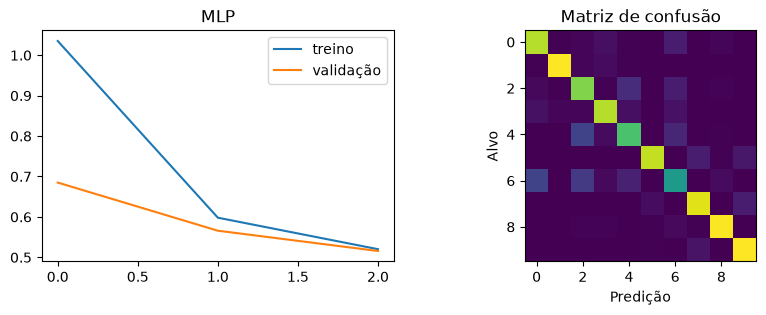

MLP acurácia: 0.82 parâmetros treináveis: 203530


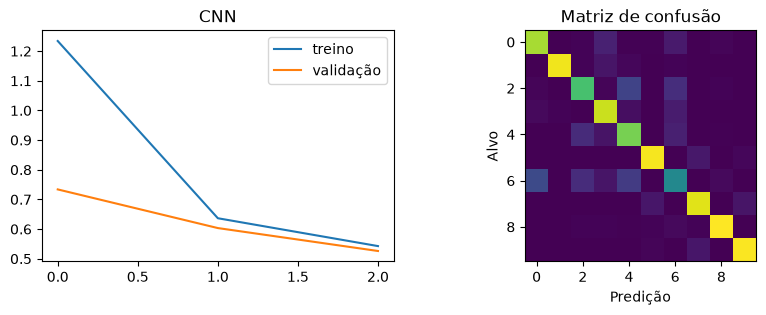

CNN acurácia: 0.8082 parâmetros treináveis: 20490


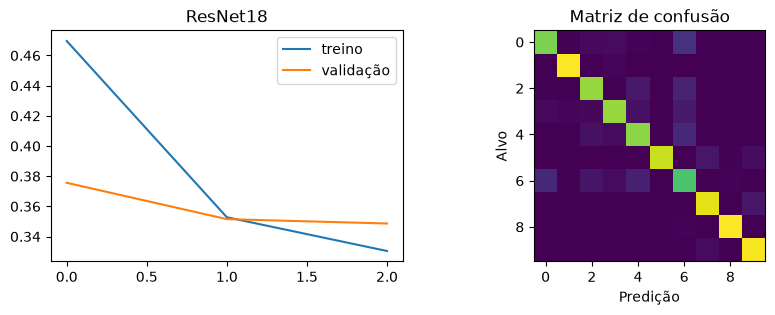

ResNet18 acurácia: 0.8707 parâmetros treináveis: 5130


In [13]:
import matplotlib.pyplot as plt
results = {}
for name, (model, loader) in trained.items():
    result = predict(model, loader, DEVICE)
    results[name] = result
    cm = torch.bincount(result['targets'] * 10 + result['preds'], minlength=100).reshape(10,10)
    fig, axes = plt.subplots(1,2,figsize=(10,3))
    axes[0].plot(histories[name]['train_loss'], label='treino')
    axes[0].plot(histories[name]['val_loss'], label='validação')
    axes[0].legend(); axes[0].set_title(name)
    axes[1].imshow(cm); axes[1].set_title('Matriz de confusão')
    axes[1].set_xlabel('Predição'); axes[1].set_ylabel('Alvo')
    plt.show()
    print(name, 'acurácia:', round(result['accuracy'],4),
          'parâmetros treináveis:', sum(p.numel() for p in model.parameters() if p.requires_grad))
